**Data Cleaning Project**
*This project sets the foundation of data science. Here we are to clean a hospital messy dataset obtained from kaggle.At the end of this project, you will be able to; import a dataset, view its contain with the use pandas functions, use a way of handling missing values and describe the data to non-technical people through graphs and plots.*

In [1]:
#importing requires modules
import os
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
# loading the uncleaned/raw dataset and viewing its content 
raw_data = pd.read_csv('multi_hospital_lab_results.csv')
raw_data.head(10)

,hospital,patient_id,test_name,test_value,unit,reference_range,collection_date
0,Hospital_A,1966,Fasting Glucose,8.56,mmol/L,70-99,2025-08-15
1,Hospital_C,1826,Glucose,-999,mmol/L,70-99,2024-07-04
2,Hospital_A,1606,Cholesterol,6.45,mmol/L,125-200,2024-11-13
3,Hospital_B,1277,Fasting Glucose,-999,mmol/L,3.9-5.5,2024-04-29
4,Hospital_A,1841,Serum Cholesterol,5.61,mmol/L,<200,2024-08-05
5,Hospital_A,1738,Glycated Hemoglobin,7.0,%,<5.7%,2024-12-23
6,Hospital_C,1061,Hemoglobin A1c,5.2,%,4.0-5.6%,2025-05-22
7,Hospital_C,1752,Glycated Hemoglobin,6.9,%,Normal < 6,2024-08-30
8,Hospital_B,1149,Blood Sugar,80.77415407811968,mg/dL,70-99,2026-01-21
9,Hospital_A,1335,Total Chol,208.94318817997245,mg/dL,125-200,2025-09-08


In [3]:
# checking for info
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   hospital         1500 non-null   str  
 1   patient_id       1500 non-null   int64
 2   test_name        1500 non-null   str  
 3   test_value       1461 non-null   str  
 4   unit             1500 non-null   str  
 5   reference_range  1500 non-null   str  
 6   collection_date  1500 non-null   str  
dtypes: int64(1), str(6)
memory usage: 82.2 KB


In [4]:
#accessing some describtions about our dataset
raw_data.describe()

,patient_id
count,1500.000000
mean,1503.090667
std,288.548052
min,1000.000000
25%,1263.500000
50%,1504.500000
75%,1741.000000
max,2000.000000


In [5]:
# checking for missing values(NAN) in each column
raw_data.isnull().sum()

hospital            0
patient_id          0
test_name           0
test_value         39
unit                0
reference_range     0
collection_date     0
dtype: int64

In [6]:
# creating a copy of the data before applying changes(cleaning). NB: this help for comparison
df = raw_data.copy()

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
#setting placeholders to nan / handling missing values
# -999 and 'not collected' are placeholders for missing vlaues not real results
df['test_value'] = pd.to_numeric(df['test_value'], errors= 'coerce')
df['test_value'] = df['test_value'].replace(-999, np.nan)

In [9]:
# rebuilding test_names to reduce naming redundancy
test_names = {
    'Blood Sugar': 'Glucose',
    'Fasting Glucose': 'Glucose',
    'Glucose': 'Glucose',
    'Cholesterol': 'Cholesterol',
    'Serum Cholesterol': 'Cholesterol',
    'Total Chol': 'Cholesterol',
    'HbA1c': 'HbA1c', 
    'Hemoglobin A1c': 'HbA1c',
    'Glycated Hemoglobin': 'HbA1c'
}
df['test_name'] = df['test_name'].map(test_names)
df['test_name'].value_counts()

test_name
HbA1c          511
Cholesterol    506
Glucose        483
Name: count, dtype: int64

In [10]:
# keeping one unit for all test_values using "vectorized boolean masking"
for col in ['hospital', 'test_name', 'unit']:
    df[col] = df[col].str.strip()
df['test_name'] = df['test_name'].map(test_names)
assert df['test_name'].notna().all()
glucose_mask = (df['unit'] == 'mg/dL') & (df['test_name'] == 'Glucose')
df.loc[glucose_mask, 'test_value'] = df.loc[glucose_mask, 'test_value'] / 18
df.loc[glucose_mask, 'unit'] = 'mmol/L'

chol_mask = (df['unit'] == 'mg/dL') & (df['test_name'] == 'Cholesterol')
df.loc[chol_mask, 'test_value'] = df.loc[chol_mask, 'test_value']/38.67
df.loc[chol_mask, 'unit'] = 'mmol/L'

df['unit'].value_counts()

unit
mmol/L    989
%         511
Name: count, dtype: int64

In [11]:
#removing outliers by setting them to NAN. 
outliers = df[df['test_value'] > 30]
print(len(outliers))                                   # expect about 5
print(outliers[['hospital', 'test_name', 'test_value']])
df.loc[df['test_value'] > 30, 'test_value'] = np.nan
print(df['test_value'].isna().sum())                   # expect about 106


7
        hospital test_name  test_value
35    Hospital_B   Glucose       500.0
496   Hospital_C   Glucose       500.0
503   Hospital_B   Glucose       500.0
1193  Hospital_B   Glucose      1860.0
1207  Hospital_A   Glucose       500.0
1298  Hospital_A   Glucose       500.0
1320  Hospital_A   Glucose       500.0
108


In [12]:
# spliting range into low and high ref
ranges = df["reference_range"].str.extract(r'(\d+\.?\d*)\s*-\s*(\d+\.?\d*)')
limits = df["reference_range"].str.extract(r'<\s*(\d+\.?\d*)')

df["ref_low"] = pd.to_numeric(ranges[0])
df["ref_high"] = pd.to_numeric(ranges[1]).fillna(pd.to_numeric(limits[0]))
df['ref_high'].isna().sum()

np.int64(0)

In [13]:
# ref_high and ref_low values to the unit mmol/L
for test, factor in [('Glucose', 18), ('Cholesterol', 38.67)]:
    m = (df['test_name'] == test) & (df['ref_high'] > 20)
    df.loc[m, ['ref_low', 'ref_high']] = df.loc[m, ['ref_low', 'ref_high']] / factor


In [14]:
# setting up for plot creation
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})
os.makedirs("figures", exist_ok=True)

def save_fig(fig, name):
    """Tidy layout and save a high-resolution copy for the README."""
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png", dpi=300, bbox_inches="tight")


**Plot 1.**
*what was wrong with the raw data?
Here we will lay down evidence of our original dataset containing missing values. 
This could be a result of the dataset creator as our dataset has a high percent chance of being synthetic.*

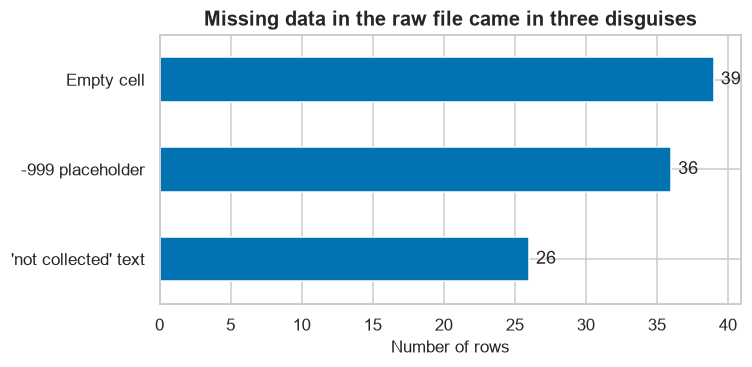

In [15]:
# Plot 1.
raw_vals = raw_data["test_value"]
missing_types = pd.Series({
    "-999 placeholder": raw_vals.eq("-999").sum(),
    "'not collected' text": raw_vals.eq("not collected").sum(),
    "Empty cell": raw_vals.isna().sum(),
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
missing_types.plot.barh(ax=ax, color=sns.color_palette()[0])
ax.set_title("Missing data in the raw file came in three disguises")
ax.set_xlabel("Number of rows")
for i, v in enumerate(missing_types):
    ax.text(v + 0.5, i, str(v), va="center")
save_fig(fig, "01_missing_types")



**Plot 2.**
*Do hospitals differ in test values?*
*This plot shows how each test varies in each hospital.
We can see from the graph that the different tests results are very similar in the various hospitals*

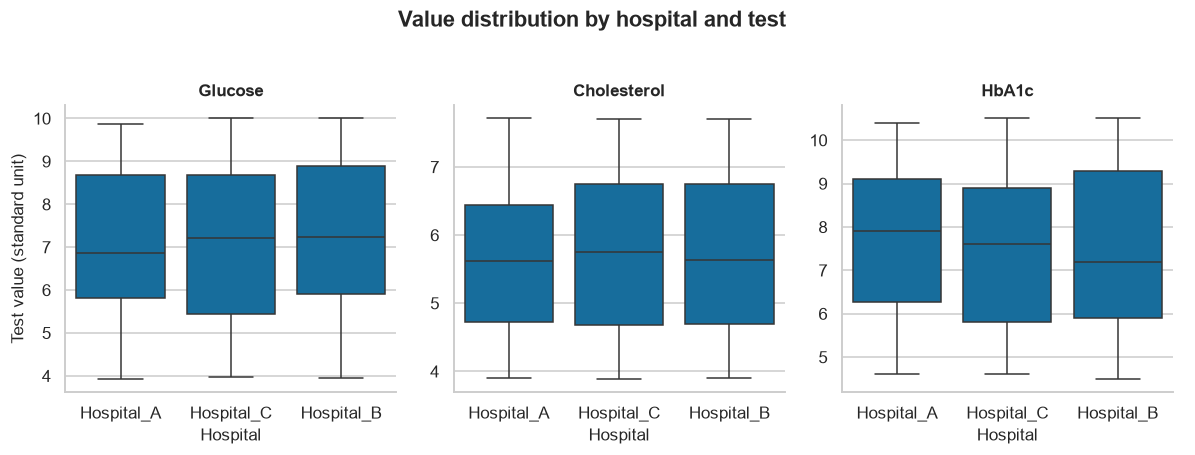

In [16]:
# Plot 2.

g = sns.catplot(data=df, x="hospital", y="test_value", col="test_name",
                kind="box", sharey=False, height=4, aspect=0.9)
g.set_titles("{col_name}")
g.set_axis_labels("Hospital", "Test value (standard unit)")
g.figure.suptitle("Value distribution by hospital and test", y=1.03, fontweight="bold")
save_fig(g.figure, "02_boxplot_hospital")

**Plot 3.**
*How are values distributed compares with the normal limit?*
*Here we see how the values are distributed compared with the normal limit.
From the graph we see that many results are higher that the normal this might be because the dataset is synthetic or people who came to the various hospitals had higher results(were unhealthy I guess)*

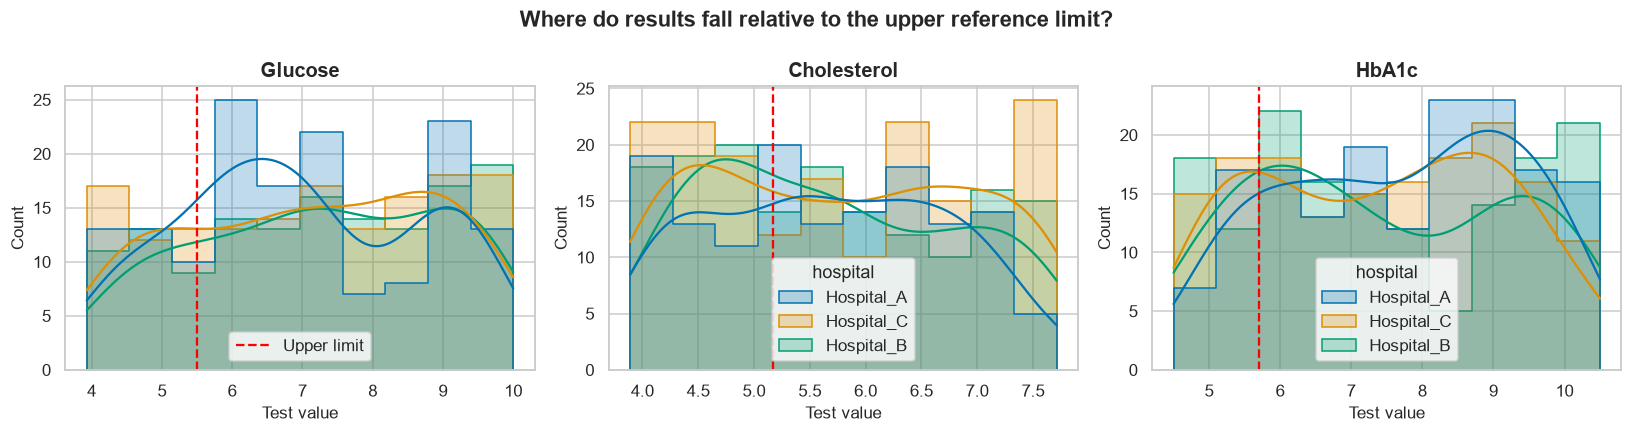

In [17]:
# Plot 3.
tests = df['test_name'].dropna().unique()
fig, axes = plt.subplots(1, len(tests), figsize=(5 * len(tests), 4))
for ax, t in zip(axes, tests):
    sub = df[df["test_name"] == t]
    sns.histplot(data=sub, x="test_value", hue="hospital",
                 element="step", kde=True, ax=ax)
    ax.axvline(sub["ref_high"].median(), color="red", ls="--", label="Upper limit")
    ax.set_title(t)
    ax.set_xlabel("Test value")
axes[0].legend()
fig.suptitle("Where do results fall relative to the upper reference limit?",
             fontweight="bold")
save_fig(fig, "03_distribution_vs_limit")

**Plot 4.**
*Which hospital has more abnormal results?This plot will show us which hospital has the most abnormal results in each of the taken tests.*

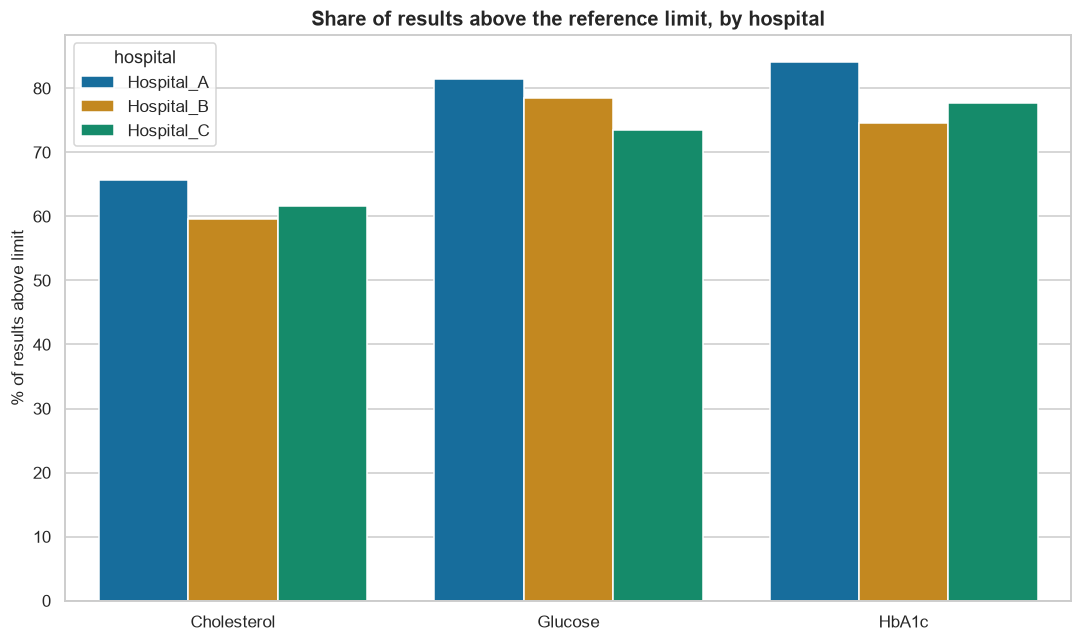

In [18]:
# plot 4.
df_valid = df.dropna(subset=['test_value']).copy()
df_valid["is_high"] = df_valid["test_value"] > df_valid["ref_high"]
rate = (df_valid.groupby(["test_name", "hospital"])["is_high"]
          .mean().mul(100).reset_index(name="pct_high"))
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=rate, x="test_name", y="pct_high", hue="hospital", ax=ax)
ax.set_title("Share of results above the reference limit, by hospital")
ax.set_xlabel("")
ax.set_ylabel("% of results above limit")
save_fig(fig, "04_abnormal_rate")

**Plot 5.**
*Is there a pattern or gap in the collection?Here we can view the median of each test results. This median is determined monthly.*

datetime64[us]
0


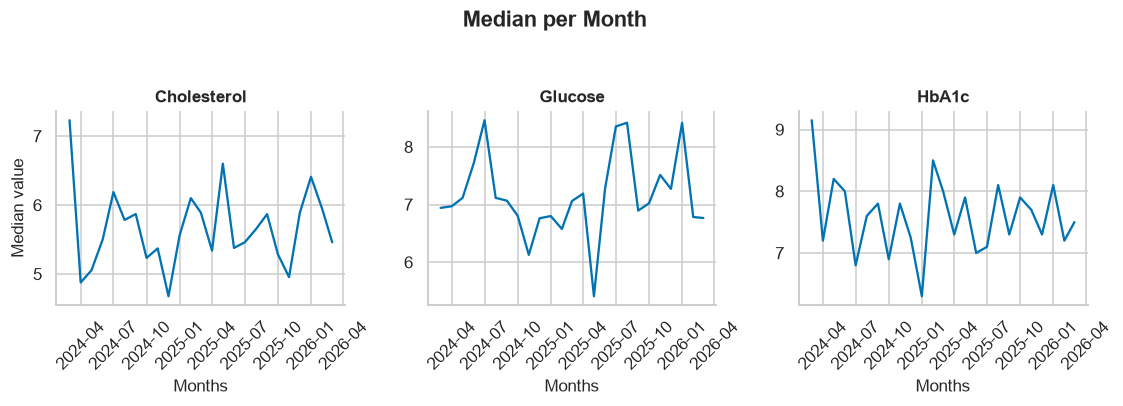

In [19]:
# Plot 5.
# is there a pattern or gap in collection
df["collection_date"] = pd.to_datetime(df["collection_date"], errors="coerce")
print(df["collection_date"].dtype)          # should be datetime64[ns]
print(df["collection_date"].isna().sum())   # should be 0
df["month"] = df["collection_date"].dt.to_period("M").dt.to_timestamp()
monthly = (df.groupby(["month", "test_name"])["test_value"]
             .median().reset_index())

g = sns.relplot(data=monthly, x="month", y="test_value", col="test_name",
                kind="line", facet_kws={"sharey": False}, height=3.5)
g.set_titles("{col_name}")
g.set_axis_labels("Months", "Median value")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)
g.figure.suptitle("Median per Month", y=1.05, fontweight="bold")
save_fig(g.figure, "05_monthly_trend")

**Plot 6.**
*Are there gaps in the collection?
This plot shows how many results were collected each month.*

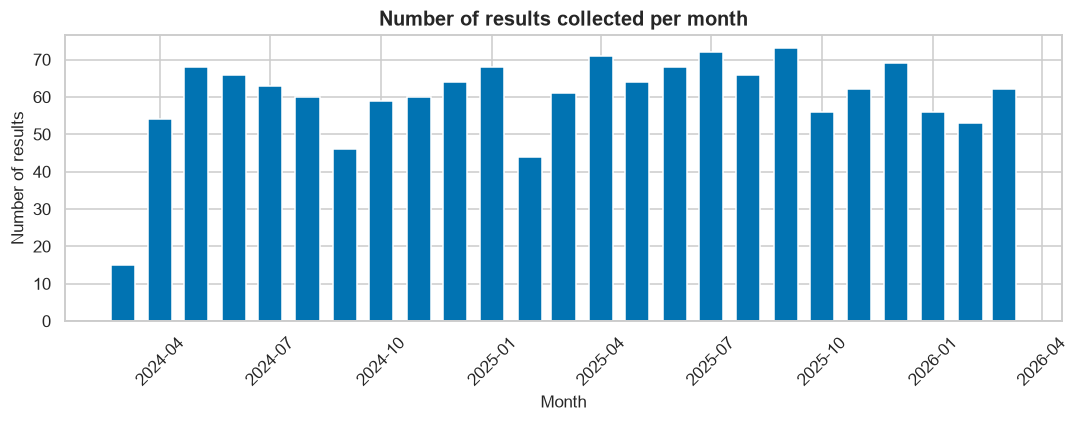

In [20]:
# Plot 6. results collected per month
all_months = pd.date_range(df["month"].min(), df["month"].max(), freq="MS")
counts = df.groupby("month").size().reindex(all_months, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(counts.index, counts.values, width=20)
ax.set_title("Number of results collected per month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of results")
ax.tick_params(axis="x", rotation=45)
save_fig(fig, "06_collection_per_month")

In [23]:
print(counts.sort_values().head(10))

2024-03-01    15
2025-02-01    44
2024-09-01    46
2026-02-01    53
2024-04-01    54
2025-10-01    56
2026-01-01    56
2024-10-01    59
2024-11-01    60
2024-08-01    60
dtype: int64


**LIMITATIONS.**
*This dataset has a high probability of being synthetic hence the presence of so many placeholders and unrealistic values.*


In [21]:
df.to_csv('cleaned_lab_results.csv', index=False)

**FINDINGS**
*Throughout this data cleaning project, I found out that the dataset had 101 missing values which came in disguised form(empty cells, -999 placeholders and not collected text) “7 glucose values above 30 were treated as outliers 6 of which were of value 500 and set to missing".*
*From plot 2: the three hospitals’ values look similar.Also, I discovered that many people had test results above the normal limit.Hospital A has the highest share above the limit in all three tests, differences are modest and haven’t been tested statistically. If our dataset is synthetic, this explains such abnormal values.Else, a high percentage of the population is unhealthy(a guess from if the dataset is real).*
*While plot 5 show ours how the median of our results changes each months, we can visualise that the monthly medians fluctuate for all three tests, with no clear trend.*
*From plot 6, Collection was steady at about 55 to 70 results per month, with no empty months.The lowest months were March 2024 (15, a partial first month), February 2025 (44) and September 2024 (46).*